<a href="https://colab.research.google.com/github/trsantana79/projeto_dissertacao/blob/main/Exp1_RF_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reprodução do Estudo de Caso (Seção 5), Experimento 1: Random Forest e XGBoost

Referência: SANTOS, J. C. dos. *Aprendizado de máquina aplicado à predição de falhas de software na computação em nuvem*. UFRPE, 2023.

**Experimento 1 do artigo:** Google Cluster Data 2011 v2, primeiros 14 dias (treino: dias 1 a 10; teste: dias 11 a 14), tempos de disco incluídos, dias com muitas falhas mantidos. Rótulo: tarefa **falha** (evento 3, classe positiva) ou **finalizada** (evento 4). Undersampling apenas no treino. O modelo do artigo é uma Árvore de Decisão (Acurácia 96%, Recall 97%, Precisão 95%, F1 96%, médias macro); aqui ela entra como *baseline* de conferência, ao lado de Random Forest e XGBoost.

O notebook segue as duas etapas do artigo: (1) treino com as 18 variáveis para obter a importância; (2) retreino com as variáveis mais importantes.

In [ ]:
import sys, subprocess, time, warnings
EM_COLAB = 'google.colab' in sys.modules
if EM_COLAB:   # no Colab, garante os pacotes; localmente use: pip install xgboost imbalanced-learn
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'xgboost', 'imbalanced-learn'])

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, accuracy_score, precision_recall_fscore_support)
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")
SEED = 0

## 1. Dados
Gere o `exp1_base.parquet` com o script `preparar_exp1.py` (no seu computador, a partir dos CSVs originais). O notebook detecta o ambiente: no **Colab** lê do Google Drive; no **VS Code** (local) lê do disco. Ajuste os dois caminhos abaixo.

In [ ]:
if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    CAMINHO = '/content/drive/MyDrive/Mestrado/exp1_base.parquet'   # <- ajuste (Colab)
    SAIDA_CSV = '/content/drive/MyDrive/Mestrado/resultados_exp1.csv'
else:
    CAMINHO = r'D:\Dataset\clusterdata-2011\exp1_base.parquet'      # <- ajuste (local)
    SAIDA_CSV = 'resultados_exp1.csv'                               # salva na pasta do notebook

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_parquet(CAMINHO)
FEATURES = [c for c in df.columns if c not in ('job_id', 'task_index', 'dia', 'falha')]
df[FEATURES] = df[FEATURES].astype('float32')
print(df.shape, '| variáveis:', len(FEATURES))
df.head()

(18073242, 22) | variáveis: 18


,job_id,task_index,dia,falha,priority,cpu_req,ram_req,disk_req,cpu_rate,canonical_mem,...,total_cache,max_mem,disk_time,disk_space,max_cpu,max_disk_time,cpi,mai,sampled_cpu,duracao
0,6351888587,979,13,1,4.0,0.09375,0.01590,0.000038,0.003093,0.001496,...,0.000310,0.001861,0.002020,0.000003,0.044724,0.016030,2.397971,0.005980,0.002853,14954.0
1,6353467895,984,13,0,4.0,0.02499,0.01163,0.000386,0.010172,0.003591,...,0.000534,0.003983,0.000936,0.000000,0.098972,0.031794,1.973000,0.005614,0.003424,104.0
2,6353467895,880,13,0,4.0,0.02499,0.01163,0.000386,0.010073,0.003481,...,0.000133,0.004179,0.002786,0.000000,0.067482,0.025450,2.605000,0.008698,0.000791,106.0
3,6353467895,588,13,0,4.0,0.02499,0.01163,0.000386,0.009094,0.003143,...,0.000093,0.003671,0.001220,0.000000,0.085683,0.019390,2.261500,0.007216,0.001520,110.0
4,6353467895,175,13,0,4.0,0.02499,0.01163,0.000386,0.010258,0.004136,...,0.000279,0.005364,0.000566,0.000000,0.096010,0.029490,2.678500,0.008238,0.000664,130.0


## 2. Divisão temporal e undersampling

Treino: dias 1 a 10. Teste: dias 11 a 14, **com a proporção original das classes** (balancear o teste superestimaria o desempenho). Conferência com a Tabela 6 do artigo: treino balanceado com 5.289.766 registros (2 × 2.644.883) e teste com 3.937.751 (2.720.497 falhas e 1.217.254 finalizadas). Diferenças pequenas são esperadas; diferenças grandes indicam problema no pré-processamento.

In [ ]:
treino = df[df.dia <= 10]
teste  = df[(df.dia >= 11) & (df.dia <= 14)]
X_te, y_te = teste[FEATURES], teste['falha'].values

rus = RandomUnderSampler(random_state=SEED)
X_tr, y_tr = rus.fit_resample(treino[FEATURES], treino['falha'].values)

print('Treino original :', np.bincount(treino['falha']), '(finalizada, falha)')
print('Treino balanceado:', np.bincount(y_tr), '| total', len(y_tr))
print('Teste           :', np.bincount(y_te), '| total', len(y_te))

Treino original : [5383563 7274594] (finalizada, falha)
Treino balanceado: [5383563 5383563] | total 10767126
Teste           : [1566936 3848149] | total 5415085


## 3. Função de avaliação
Métricas médias em **macro** (é o que reproduz a Tabela 9 do artigo), mais as métricas por classe, matriz de confusão normalizada pelo total e tempos de treino e previsão.

In [ ]:
RESULTADOS = []

def avaliar(nome, modelo, cols, Xtr=None, ytr=None, mostrar=True):
    Xtr = X_tr if Xtr is None else Xtr
    ytr = y_tr if ytr is None else ytr
    t0 = time.time(); modelo.fit(Xtr[cols], ytr); t_fit = time.time() - t0
    t0 = time.time(); pred = modelo.predict(X_te[cols]); t_pred = time.time() - t0
    proba = modelo.predict_proba(X_te[cols])[:, 1]
    p, r, f, _ = precision_recall_fscore_support(y_te, pred, average='macro')
    RESULTADOS.append(dict(modelo=nome, n_vars=len(cols), acuracia=accuracy_score(y_te, pred),
                           recall=r, precisao=p, f1=f, auc=roc_auc_score(y_te, proba),
                           treino_s=t_fit, previsao_s=t_pred))
    if mostrar:
        print(f'=== {nome} ({len(cols)} variáveis) | treino {t_fit:.1f}s | previsão {t_pred:.2f}s')
        print(classification_report(y_te, pred, target_names=['Finalizada', 'Falha'], digits=3))
        cm = confusion_matrix(y_te, pred, labels=[1, 0]); cm = cm / cm.sum()
        ConfusionMatrixDisplay(cm, display_labels=['Falha', 'Finalizada']).plot(
            cmap='viridis', values_format='.2%', colorbar=False)
        plt.title(nome); plt.xlabel('Classe prevista'); plt.ylabel('Classe real'); plt.show()
    return modelo

def importancias(modelo, cols, titulo):
    s = pd.Series(modelo.feature_importances_, index=cols).sort_values()
    s.plot.barh(figsize=(6, 5), title=titulo); plt.tight_layout(); plt.show()
    return s.sort_values(ascending=False)

## 4. Etapa 1: todas as variáveis (hiperparâmetros iniciais)

O artigo usa árvore com `max_depth=10` e `max_features=None` no Experimento 1 (Tabela 7). Para RF e XGBoost não há valores no artigo; os abaixo são um ponto de partida e podem ser variados nos exercícios.

=== Árvore de Decisão (etapa 1) (18 variáveis) | treino 231.6s | previsão 0.48s
              precision    recall  f1-score   support

  Finalizada      0.899     0.989     0.942   1566936
       Falha      0.995     0.955     0.975   3848149

    accuracy                          0.965   5415085
   macro avg      0.947     0.972     0.958   5415085
weighted avg      0.968     0.965     0.965   5415085



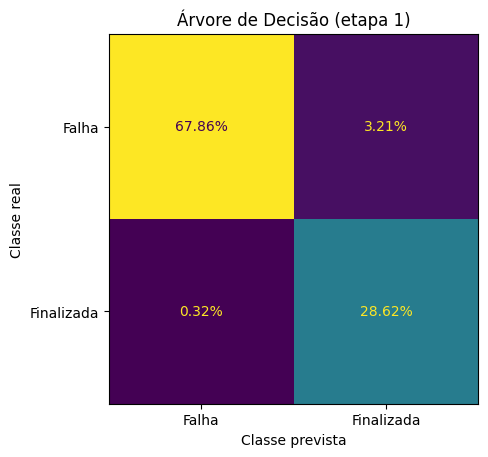

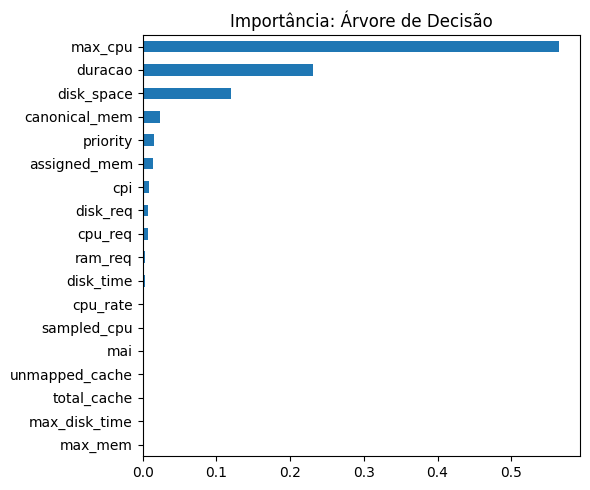

In [ ]:
dt1  = avaliar('Árvore de Decisão (etapa 1)', DecisionTreeClassifier(max_depth=10, random_state=SEED), FEATURES)
imp_dt = importancias(dt1, FEATURES, 'Importância: Árvore de Decisão')

=== Random Forest (etapa 1) (18 variáveis) | treino 637.8s | previsão 3.97s
              precision    recall  f1-score   support

  Finalizada      0.902     0.993     0.945   1566936
       Falha      0.997     0.956     0.976   3848149

    accuracy                          0.967   5415085
   macro avg      0.950     0.974     0.961   5415085
weighted avg      0.969     0.967     0.967   5415085



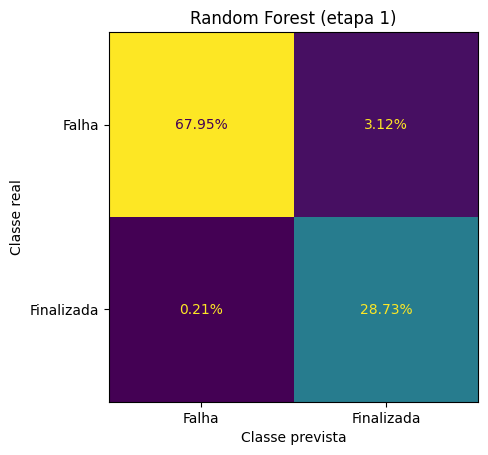

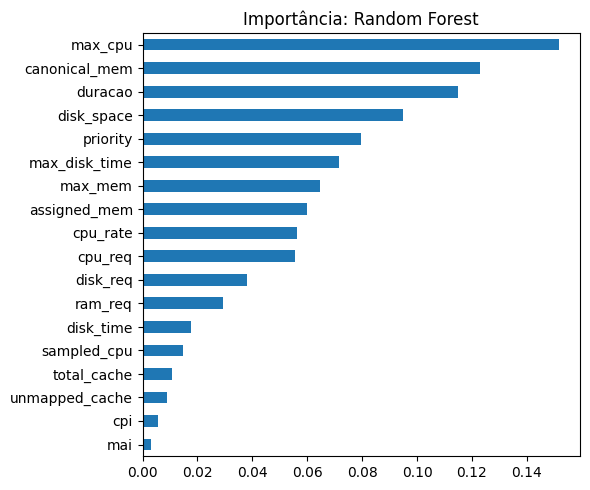

In [ ]:
rf1  = avaliar('Random Forest (etapa 1)', RandomForestClassifier(
            n_estimators=100, max_depth=10, max_features='sqrt', n_jobs=-1, random_state=SEED), FEATURES)
imp_rf = importancias(rf1, FEATURES, 'Importância: Random Forest')

=== XGBoost (etapa 1) (18 variáveis) | treino 30.6s | previsão 1.82s
              precision    recall  f1-score   support

  Finalizada      0.949     0.988     0.968   1566936
       Falha      0.995     0.978     0.987   3848149

    accuracy                          0.981   5415085
   macro avg      0.972     0.983     0.978   5415085
weighted avg      0.982     0.981     0.981   5415085



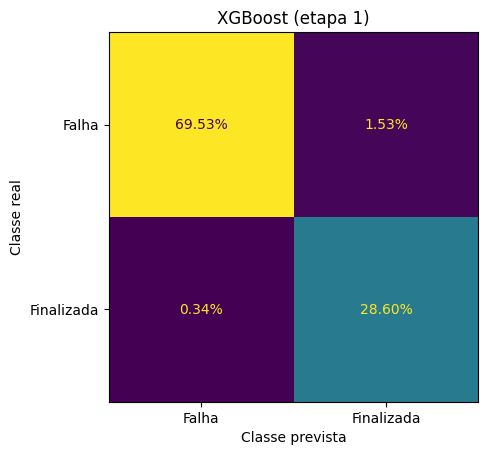

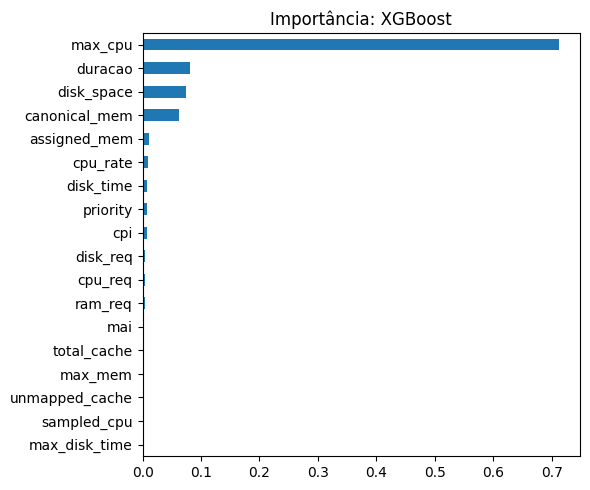

In [ ]:
xgb1 = avaliar('XGBoost (etapa 1)', XGBClassifier(
            n_estimators=100, max_depth=6, learning_rate=0.1, tree_method='hist',
            n_jobs=-1, random_state=SEED), FEATURES)
imp_xgb = importancias(xgb1, FEATURES, 'Importância: XGBoost')

In [ ]:
K = 4   # o artigo manteve as 4 variáveis mais preditivas no Experimento 1
top = {'Árvore de Decisão': list(imp_dt.index[:K]),
       'Random Forest': list(imp_rf.index[:K]),
       'XGBoost': list(imp_xgb.index[:K])}
VARS_ARTIGO = ['cpu_req', 'disk_req', 'max_cpu', 'max_disk_time']   # CPU solicitada, disco solicitado, CPU máxima, tempo máximo de disco
for k, v in top.items(): print(f'{k:20s}', v)
print(f'{"Artigo (DT)":20s}', VARS_ARTIGO)

Árvore de Decisão    ['max_cpu', 'duracao', 'disk_space', 'canonical_mem']
Random Forest        ['max_cpu', 'canonical_mem', 'duracao', 'disk_space']
XGBoost              ['max_cpu', 'duracao', 'disk_space', 'canonical_mem']
Artigo (DT)          ['cpu_req', 'disk_req', 'max_cpu', 'max_disk_time']


## 5. Etapa 2: retreino com as variáveis mais importantes
Hiperparâmetros finais da árvore no artigo: `max_depth=6`, `max_features='sqrt'` (Tabela 8). Para RF e XGBoost mantive a profundidade 6 para comparação direta com a árvore.

=== Árvore de Decisão (4 variáveis) | treino 22.2s | previsão 0.19s
              precision    recall  f1-score   support

  Finalizada      0.882     0.990     0.933   1566936
       Falha      0.996     0.946     0.970   3848149

    accuracy                          0.959   5415085
   macro avg      0.939     0.968     0.951   5415085
weighted avg      0.963     0.959     0.959   5415085



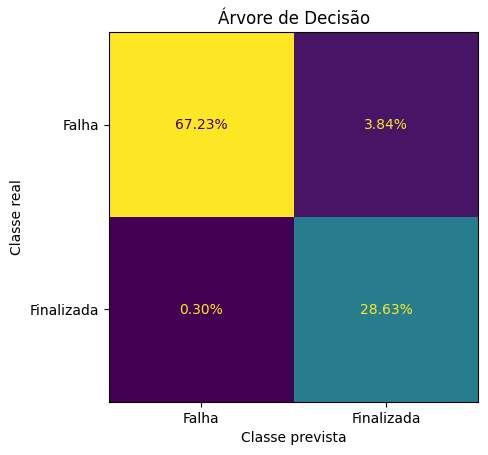

=== Random Forest (4 variáveis) | treino 264.5s | previsão 2.47s
              precision    recall  f1-score   support

  Finalizada      0.885     0.986     0.933   1566936
       Falha      0.994     0.948     0.971   3848149

    accuracy                          0.959   5415085
   macro avg      0.940     0.967     0.952   5415085
weighted avg      0.963     0.959     0.960   5415085



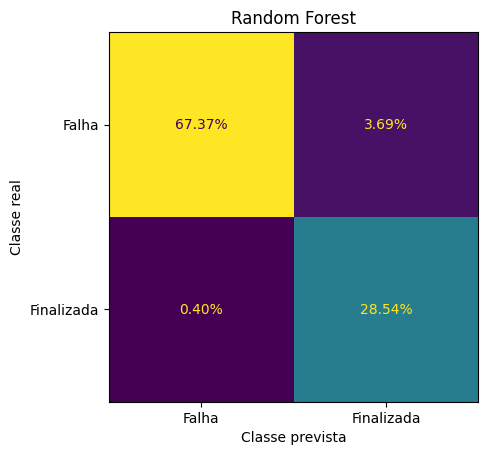

=== XGBoost (4 variáveis) | treino 23.9s | previsão 1.62s
              precision    recall  f1-score   support

  Finalizada      0.885     0.989     0.934   1566936
       Falha      0.995     0.948     0.971   3848149

    accuracy                          0.960   5415085
   macro avg      0.940     0.968     0.953   5415085
weighted avg      0.964     0.960     0.960   5415085



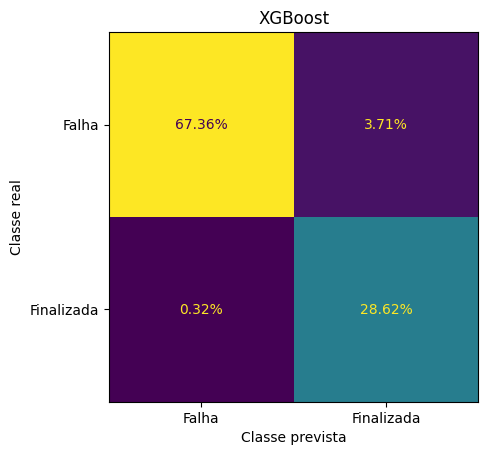

In [ ]:
RESULTADOS.clear()
dt2  = avaliar('Árvore de Decisão', DecisionTreeClassifier(max_depth=6, max_features='sqrt', random_state=SEED), top['Árvore de Decisão'])
rf2  = avaliar('Random Forest', RandomForestClassifier(n_estimators=100, max_depth=6, max_features='sqrt',
                                                        n_jobs=-1, random_state=SEED), top['Random Forest'])
xgb2 = avaliar('XGBoost', XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, tree_method='hist',
                                         n_jobs=-1, random_state=SEED), top['XGBoost'])

### 5.1 Variáveis do artigo
Mesmo conjunto de 4 variáveis usado por Santos (2023), para isolar o efeito do algoritmo.

In [ ]:
dt3  = avaliar('DT, vars do artigo', DecisionTreeClassifier(max_depth=6, max_features='sqrt', random_state=SEED), VARS_ARTIGO, mostrar=False)
rf3  = avaliar('RF, vars do artigo', RandomForestClassifier(n_estimators=100, max_depth=6, max_features='sqrt',
                                                             n_jobs=-1, random_state=SEED), VARS_ARTIGO, mostrar=False)
xgb3 = avaliar('XGB, vars do artigo', XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                                                     tree_method='hist', n_jobs=-1, random_state=SEED), VARS_ARTIGO, mostrar=False)

## 6. Comparação
Linha de referência: Tabela 9 do artigo, Experimento 1 (árvore de decisão): acurácia 96%, recall 97%, precisão 95%, F1 96%, treino 11,51 s, previsão 0,30 s (hardware diferente, os tempos não são comparáveis em valor absoluto).

In [ ]:
tab = pd.DataFrame(RESULTADOS)
ref = pd.DataFrame([dict(modelo='ARTIGO: Árvore de Decisão', n_vars=4, acuracia=.96, recall=.97, precisao=.95,
                         f1=.96, auc=np.nan, treino_s=11.51, previsao_s=.30)])
tab = pd.concat([ref, tab], ignore_index=True)
tab.style.format({'acuracia': '{:.3f}', 'recall': '{:.3f}', 'precisao': '{:.3f}', 'f1': '{:.3f}',
                  'auc': '{:.3f}', 'treino_s': '{:.2f}', 'previsao_s': '{:.2f}'})

,modelo,n_vars,acuracia,recall,precisao,f1,auc,treino_s,previsao_s
0,ARTIGO: Árvore de Decisão,4,0.960,0.970,0.950,0.960,nan,11.51,0.30
1,Árvore de Decisão,4,0.959,0.968,0.939,0.951,0.991,22.22,0.19
2,Random Forest,4,0.959,0.967,0.940,0.952,0.995,264.54,2.47
3,XGBoost,4,0.960,0.968,0.940,0.953,0.996,23.89,1.62
4,"DT, vars do artigo",4,0.914,0.936,0.886,0.903,0.958,15.97,0.20
5,"RF, vars do artigo",4,0.924,0.945,0.896,0.914,0.987,210.82,2.79
6,"XGB, vars do artigo",4,0.971,0.978,0.956,0.966,0.992,24.19,1.61


In [ ]:
tab.to_csv(SAIDA_CSV, index=False)
print('salvo em', SAIDA_CSV)

salvo em /content/drive/MyDrive/Mestrado/resultados_exp1.csv


## 7. Para estudar

1. **Desbalanceamento no teste.** Por que no Experimento 1 a classe majoritária do teste é *falha* (cerca de 69%), ao contrário dos Experimentos 2 a 4? O que isso faz com acurácia e precisão?
2. **Importância das variáveis.** As 4 variáveis escolhidas por RF e XGBoost coincidem com as da árvore? Por que a importância do XGBoost (ganho) tende a ser mais concentrada que a do RF (redução de impureza média)?
3. **Hiperparâmetros.** Varie `max_depth` (4, 6, 10, 20) e `n_estimators` (50, 100, 300) e veja o efeito em recall da classe falha e no tempo de treino.
4. **Vazamento temporal.** O artigo treina com os dias 1 a 10 e testa em 11 a 14. O que mudaria com um *split* aleatório estratificado?
5. **Sem undersampling.** Treine com o desbalanceamento original e use `class_weight='balanced'` (RF) ou `scale_pos_weight` (XGBoost).